# Classification of (kNN) — Air Quality Dataset

This notebook covers data preprocessing, kNN classification, hyperparameter experimentation ($k$ values), train/test split comparisons, and $k$-fold cross-validation.

## Task 1 — Select and Reserve a Dataset

* **Dataset Selected:** Air Quality Dataset (`air_quality_dataset.csv` sourced from Kaggle).
* **Dataset Description:** This dataset contains environmental monitoring metrics and pollutant concentrations recorded by urban air quality stations. 
* **Target Variable (`Air_Quality_Class`):** Engineered from the continuous `PM2.5` pollutant concentration using standard Air Quality Index (AQI) threshold boundaries:
  * **Good:** $\text{PM2.5} \le 35\,\mu\text{g/m}^3$
  * **Moderate:** $35 < \text{PM2.5} \le 75\,\mu\text{g/m}^3$
  * **Poor:** $\text{PM2.5} > 75\,\mu\text{g/m}^3$
* **Features:** Numerical attributes representing gaseous pollutants (e.g., $\text{NO}_2$, $\text{SO}_2$, $\text{CO}$, $\text{O}_3$, $\text{PM}_{10}$) and meteorological variables (temperature, humidity, wind speed) used to classify overall air quality.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

print("--- 1. LOADING & PREPROCESSING DATA ---")
df = pd.read_csv('air_quality_dataset.csv')
print(f"Dataset Loaded Successfully! Shape: {df.shape}")

def categorize_aqi(pm25):
    if pm25 <= 35:
        return 'Good'
    elif pm25 <= 75:
        return 'Moderate'
    else:
        return 'Poor'

df['Air_Quality_Class'] = df['PM2.5'].apply(categorize_aqi)

df.to_csv('cleaned_air_quality_dataset.csv', index=False)
print("Saved cleaned dataset: cleaned_air_quality_dataset.csv")

summary_df = df.describe().T
summary_df.to_csv('air_quality_summary_stats.csv')
print("Saved summary statistics: air_quality_summary_stats.csv")

X = df.drop(columns=['Air_Quality_Class'])
y = df['Air_Quality_Class']

print("\nClass Distribution:")
print(y.value_counts())

--- 1. LOADING & PREPROCESSING DATA ---
Dataset Loaded Successfully! Shape: (500, 10)
Saved cleaned dataset: cleaned_air_quality_dataset.csv
Saved summary statistics: air_quality_summary_stats.csv

Class Distribution:
Air_Quality_Class
Moderate    285
Poor        115
Good        100
Name: count, dtype: int64


## Task 2 — Implement and Run kNN ($k=5$)


In [2]:
print("--- TASK 2: BASE kNN MODEL (k=5) ---")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)
print(f"Base kNN Accuracy (k=5): {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

--- TASK 2: BASE kNN MODEL (k=5) ---
Base kNN Accuracy (k=5): 0.8500

Classification Report:
               precision    recall  f1-score   support

        Good       0.87      0.65      0.74        20
    Moderate       0.88      0.86      0.87        57
        Poor       0.79      1.00      0.88        23

    accuracy                           0.85       100
   macro avg       0.84      0.84      0.83       100
weighted avg       0.85      0.85      0.85       100



## Task 3 — Real-World Applications of kNN

--- TASK 4: EXPERIMENTING WITH k VALUES ---
k =  1 | Test Accuracy: 0.7700
k =  3 | Test Accuracy: 0.8600
k =  5 | Test Accuracy: 0.8500
k =  9 | Test Accuracy: 0.8600
k = 15 | Test Accuracy: 0.8700
k = 25 | Test Accuracy: 0.8400
k = 35 | Test Accuracy: 0.7800


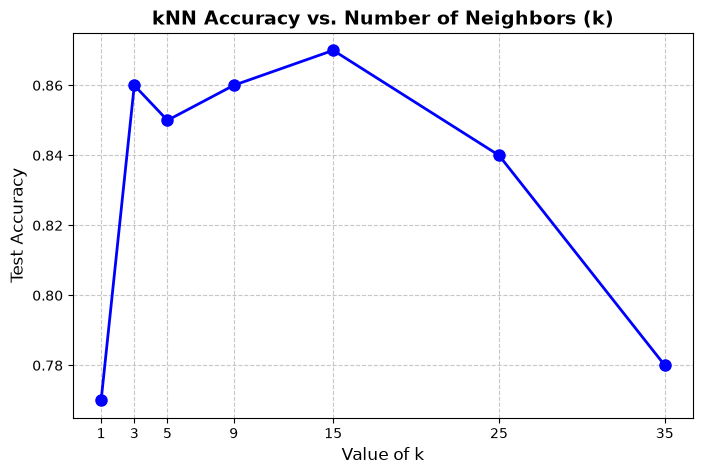

In [3]:
print("--- TASK 4: EXPERIMENTING WITH k VALUES ---")
k_values = [1, 3, 5, 9, 15, 25, 35]
accuracies = []

for k in k_values:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train_scaled, y_train)
    acc = accuracy_score(y_test, clf.predict(X_test_scaled))
    accuracies.append(acc)
    print(f"k = {k:2d} | Test Accuracy: {acc:.4f}")

# Plotting Accuracy vs k Values
plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', color='blue', linestyle='-', linewidth=2, markersize=8)
plt.title('kNN Accuracy vs. Number of Neighbors (k)', fontsize=14, fontweight='bold')
plt.xlabel('Value of k', fontsize=12)
plt.ylabel('Test Accuracy', fontsize=12)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('knn_k_values.png', dpi=300, bbox_inches='tight')
plt.show()

## Task 5 — Compare Train/Test Splits

--- TASK 5: COMPARING TRAIN/TEST SPLITS ---
Split (80/20) -> Test Accuracy: 0.8500
Split (70/30) -> Test Accuracy: 0.8067
Split (60/40) -> Test Accuracy: 0.7850


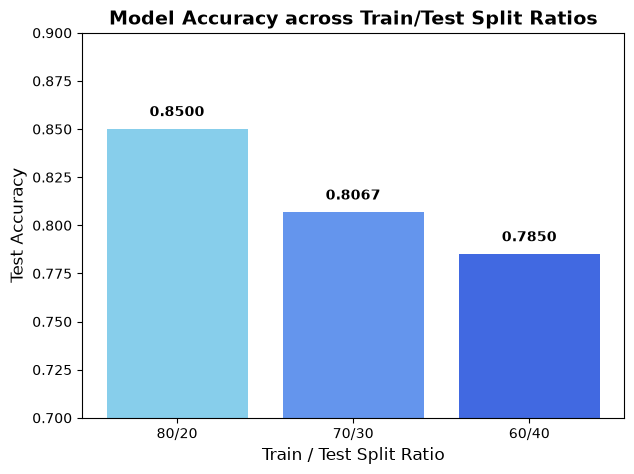

In [4]:
print("--- TASK 5: COMPARING TRAIN/TEST SPLITS ---")
split_ratios = [(0.80, 0.20), (0.70, 0.30), (0.60, 0.40)]
split_labels = ['80/20', '70/30', '60/40']
split_accuracies = []

for (train_size, test_size), label in zip(split_ratios, split_labels):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    sc = StandardScaler()
    X_tr_s = sc.fit_transform(X_tr)
    X_te_s = sc.transform(X_te)
    
    clf = KNeighborsClassifier(n_neighbors=5)
    clf.fit(X_tr_s, y_tr)
    acc = accuracy_score(y_te, clf.predict(X_te_s))
    split_accuracies.append(acc)
    print(f"Split ({label}) -> Test Accuracy: {acc:.4f}")

# Plotting Split Comparison Bar Chart
plt.figure(figsize=(7, 5))
bars = plt.bar(split_labels, split_accuracies, color=['skyblue', 'cornflowerblue', 'royalblue'])
plt.title('Model Accuracy across Train/Test Split Ratios', fontsize=14, fontweight='bold')
plt.xlabel('Train / Test Split Ratio', fontsize=12)
plt.ylabel('Test Accuracy', fontsize=12)
plt.ylim(0.7, 0.9)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')
plt.savefig('split_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Task 6 — $k$-Fold Cross-Validation


--- TASK 6: 5-FOLD CROSS-VALIDATION ---
5-Fold CV Scores: [0.75 0.81 0.78 0.72 0.84]
Mean CV Accuracy: 0.7800
Standard Deviation (Stability Metric): 0.0424


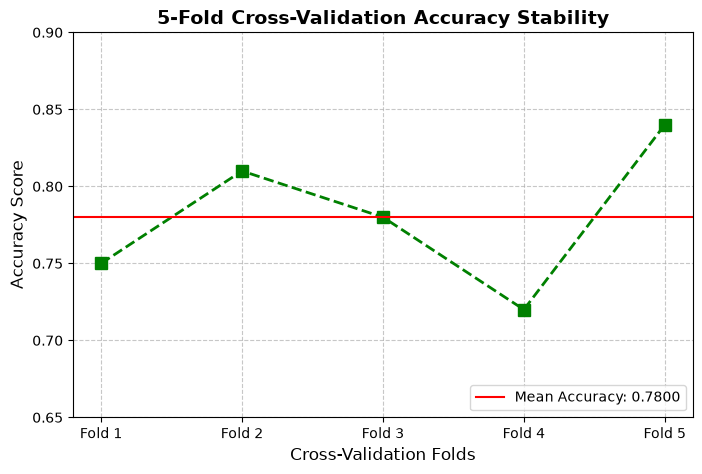

In [ ]:
print("--- TASK 6: 5-FOLD CROSS-VALIDATION ---")
X_scaled_all = scaler.fit_transform(X)
cv_scores = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_scaled_all, y, cv=5, scoring='accuracy')

print(f"5-Fold CV Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation (Stability Metric): {cv_scores.std():.4f}")

plt.figure(figsize=(8, 5))
folds = [f"Fold {i+1}" for i in range(len(cv_scores))]
plt.plot(folds, cv_scores, marker='s', color='green', linestyle='--', linewidth=2, markersize=8)
plt.axhline(y=cv_scores.mean(), color='red', linestyle='-', label=f'Mean Accuracy: {cv_scores.mean():.4f}')
plt.title('5-Fold Cross-Validation Accuracy Stability', fontsize=14, fontweight='bold')
plt.xlabel('Cross-Validation Folds', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.ylim(0.65, 0.90)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('cv_scores.png', dpi=300, bbox_inches='tight')
plt.show()